In [6]:
%pip install mediapipe
%pip install pyttsx3
%pip install requests
%pip install datetime



Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 24.3.1
[notice] To update, run: C:\Users\srini\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: pyttsx3 in c:\users\srini\appdata\local\packages\pythonsoftwarefoundation.python.3.11_qbz5n2kfra8p0\localcache\local-packages\python311\site-packages (2.98)




[notice] A new release of pip is available: 24.0 -> 24.3.1
[notice] To update, run: C:\Users\srini\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 24.3.1
[notice] To update, run: C:\Users\srini\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 24.3.1
[notice] To update, run: C:\Users\srini\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [5]:
import http.client
import os
from datetime import datetime

# ESP32 IP address (replace <esp32_ip> with your ESP32's actual IP)
esp32_ip = "192.168.29.151"

# Folder to save the captured images
save_folder = "C:/Users/srini/OneDrive/Desktop/IMAGES"

def capture_image():
    try:
        # Establish connection to ESP32
        conn = http.client.HTTPConnection(esp32_ip)
        
        # Send GET request to capture image
        conn.request("GET", "/capture")
        
        # Get the response from ESP32
        response = conn.getresponse()

        # Check if the request was successful (status code 200)
        if response.status == 200:
            # Read the image data
            image_data = response.read()

            # Create save folder if it doesn't exist
            if not os.path.exists(save_folder):
                os.makedirs(save_folder)

            # Generate a unique filename based on the current time
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            image_path = os.path.join(save_folder, f"image_{timestamp}.jpg")

            # Save the image content to a file
            with open(image_path, 'wb') as image_file:
                image_file.write(image_data)

            print(f"Image saved successfully at: {image_path}")
        else:
            print(f"Failed to capture image. Status code: {response.status}")
        
        # Close the connection
        conn.close()

    except Exception as e:
        print(f"Error occurred: {e}")

# Call the function to capture and save the image
capture_image()


KeyboardInterrupt: 

In [7]:
import math
import cv2
import numpy as np
import mediapipe as mp
import matplotlib.pyplot as plt
import pyttsx3
import requests  # For sending pose name to Blynk

# Initialize MediaPipe Pose
mp_pose = mp.solutions.pose
pose = mp_pose.Pose(static_image_mode=True, min_detection_confidence=0.75, model_complexity=2)
mp_drawing = mp.solutions.drawing_utils

# Initialize Text-to-Speech (TTS) engine
engine = pyttsx3.init()

# Blynk configuration
BLYNK_TOKEN = "sSPtEkdV263b3a1uX_zttyp7oZbCp9yf"
BLYNK_URL = f"https://blynk.cloud/external/api/update?token={BLYNK_TOKEN}&"

# Helper function to calculate angles
def calculateAngle(landmark1, landmark2, landmark3):
    x1, y1, _ = landmark1
    x2, y2, _ = landmark2
    x3, y3, _ = landmark3
    angle = math.degrees(math.atan2(y3 - y2, x3 - x2) - math.atan2(y1 - y2, x1 - x2))
    if angle < 0:
        angle += 360
    return angle

def detectPose(image, pose, display=True):
  output_image=image.copy()
  imageRGB=cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
  results=pose.process(imageRGB)
  height, width, _ = image.shape
  landmarks = []
  if results.pose_landmarks:
    mp_drawing.draw_landmarks(image=output_image, landmark_list=results.pose_landmarks, connections=mp_pose.POSE_CONNECTIONS)
    for landmark in results.pose_landmarks.landmark:
      landmarks.append((int(landmark.x*width), int(landmark.y*height),(landmark.z*width)))
  if display:
    plt.figure(figsize=[22,22])
    plt.subplot(121);plt.imshow(image[:,:,::-1]);plt.title("Original Image");plt.axis("off");
    plt.subplot(122);plt.imshow(output_image[:,:,::-1]);plt.title("Output Image");plt.axis('off');
    mp_drawing.plot_landmarks(results.pose_world_landmarks, mp_pose.POSE_CONNECTIONS)
  else:
    return output_image, landmarks

# Function to classify pose and provide feedback
def classifyPose(landmarks, output_image, display=False):
    label = "Unknown Pose"
    feedback = "Your pose needs improvement."
    color = (0, 0, 255)
    
    # Calculate angles
    left_elbow_angle = calculateAngle(landmarks[mp_pose.PoseLandmark.LEFT_SHOULDER.value],
                                      landmarks[mp_pose.PoseLandmark.LEFT_ELBOW.value],
                                      landmarks[mp_pose.PoseLandmark.LEFT_WRIST.value])
    right_elbow_angle = calculateAngle(landmarks[mp_pose.PoseLandmark.RIGHT_SHOULDER.value],
                                       landmarks[mp_pose.PoseLandmark.RIGHT_ELBOW.value],
                                       landmarks[mp_pose.PoseLandmark.RIGHT_WRIST.value])
    left_shoulder_angle = calculateAngle(landmarks[mp_pose.PoseLandmark.LEFT_ELBOW.value],
                                         landmarks[mp_pose.PoseLandmark.LEFT_SHOULDER.value],
                                         landmarks[mp_pose.PoseLandmark.LEFT_HIP.value])
    right_shoulder_angle = calculateAngle(landmarks[mp_pose.PoseLandmark.RIGHT_ELBOW.value],
                                          landmarks[mp_pose.PoseLandmark.RIGHT_SHOULDER.value],
                                          landmarks[mp_pose.PoseLandmark.RIGHT_HIP.value])
    left_knee_angle = calculateAngle(landmarks[mp_pose.PoseLandmark.LEFT_HIP.value],
                                     landmarks[mp_pose.PoseLandmark.LEFT_KNEE.value],
                                     landmarks[mp_pose.PoseLandmark.LEFT_ANKLE.value])
    right_knee_angle = calculateAngle(landmarks[mp_pose.PoseLandmark.RIGHT_HIP.value],
                                      landmarks[mp_pose.PoseLandmark.RIGHT_KNEE.value],
                                      landmarks[mp_pose.PoseLandmark.RIGHT_ANKLE.value])
    left_hip_angle = calculateAngle(landmarks[mp_pose.PoseLandmark.LEFT_SHOULDER.value],
                                 landmarks[mp_pose.PoseLandmark.LEFT_HIP.value],
                                 landmarks[mp_pose.PoseLandmark.LEFT_KNEE.value])
    right_hip_angle = calculateAngle(landmarks[mp_pose.PoseLandmark.RIGHT_SHOULDER.value],
                                 landmarks[mp_pose.PoseLandmark.RIGHT_HIP.value],
                                 landmarks[mp_pose.PoseLandmark.RIGHT_KNEE.value])
    
    print(f'Calculated angle LS:{left_shoulder_angle}')
    print(f'Calculated angle LE:{left_elbow_angle}')
    print(f'Calculated angle RE:{right_elbow_angle}')
    print(f'Calculated angle RS:{right_shoulder_angle}')
    print(f'Calculated angle LH:{left_hip_angle}')
    print(f'Calculated angle RH:{right_hip_angle}')
    print(f'Calculated angle LK1:{left_knee_angle}')
    print(f'Calculated angle RK1:{right_knee_angle}')
    print(f'Calculated angle LK2:{left_knee_angle}')
    print(f'Calculated angle RK2:{right_knee_angle}')
    
    # Pose classification logic based on calculated angles
    if 160 < left_elbow_angle < 200 or 160 < right_elbow_angle < 200:
        if 30 < left_shoulder_angle < 350 or 30 < right_shoulder_angle < 350:
            label = "Bridge Pose"
            feedback = "This is Bridge Pose. Excellent! Keep your hips elevated and maintain your balance."

        if 160 < left_shoulder_angle < 245 or 160 < right_shoulder_angle < 245:
            label = "Downward Dog Pose"
            feedback = "This is Downward Dog Pose. Nice! Keep your back straight and stretch your legs further."

    if 154 < left_elbow_angle < 198 and 168 < right_elbow_angle < 200:
        if 169 < left_hip_angle < 196 and 169 < right_hip_angle < 196:
            label = "Mountain Pose"
            feedback = "This is Mountain Pose. Good job! Maintain your posture and keep breathing."

    if 120 < left_knee_angle < 195 or 120 < right_knee_angle < 195:
        if 70 < left_shoulder_angle < 120 or 70 < right_shoulder_angle < 120:
            label = "Warrior II Pose"
            feedback = "This is Warrior II Pose. Great! Focus on stretching your arms and balancing your feet."

    if label != "Unknown Pose":
        color = (0, 255, 0)
    else:
        feedback = "Unknown Pose. Please adjust your posture."

    # Display pose label
    cv2.putText(output_image, label, (10, 40), cv2.FONT_HERSHEY_COMPLEX, 1, color, 2, cv2.LINE_AA)

    # Send pose name to Blynk
    requests.get(BLYNK_URL + f"V2={label}")

    # Provide voice feedback
    engine.say(feedback)
    engine.runAndWait()

    # Display output
    if display:
        plt.figure(figsize=[10, 10])
        plt.imshow(output_image[:, :, ::-1])
        plt.title("Output Image")
        plt.axis("off")
    else:
        return output_image, label



Calculated angle LS:90.79322002309334
Calculated angle LE:186.8000910258803
Calculated angle RE:185.41335979361318
Calculated angle RS:254.80709917977637
Calculated angle LH:152.08670118171
Calculated angle RH:246.20395943345164
Calculated angle LK1:149.6825305461902
Calculated angle RK1:124.00940901908974
Calculated angle LK2:149.6825305461902
Calculated angle RK2:124.00940901908974
Calculated angle LS:11.219358681607812
Calculated angle LE:174.89008639065898
Calculated angle RE:186.8472208068247
Calculated angle RS:348.6222563669353
Calculated angle LH:172.62294398312068
Calculated angle RH:187.18186250817334
Calculated angle LK1:185.51189810703886
Calculated angle RK1:171.59209300302032
Calculated angle LK2:185.51189810703886
Calculated angle RK2:171.59209300302032
Calculated angle LS:227.95367400489684
Calculated angle LE:190.22216863363613
Calculated angle RE:197.6410627334466
Calculated angle RS:234.15211885294187
Calculated angle LH:280.4315090828002
Calculated angle RH:275.7626

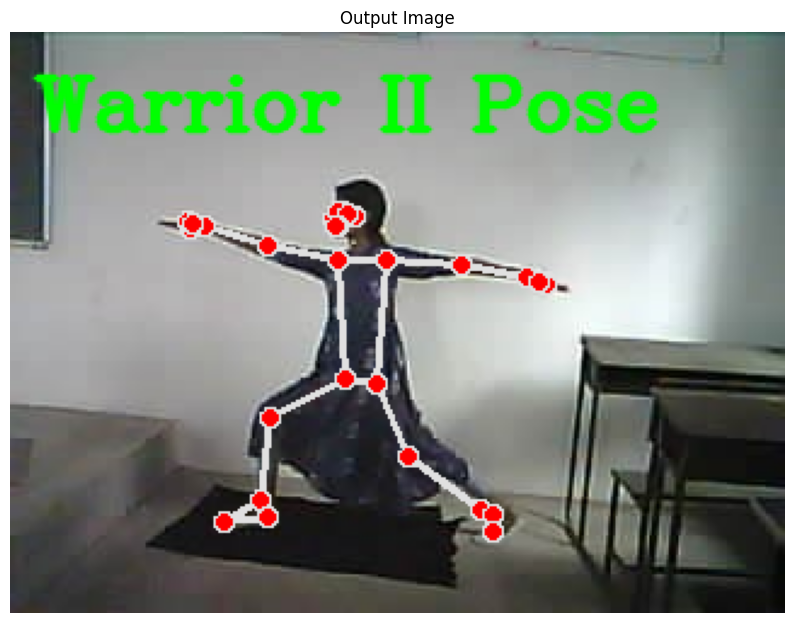

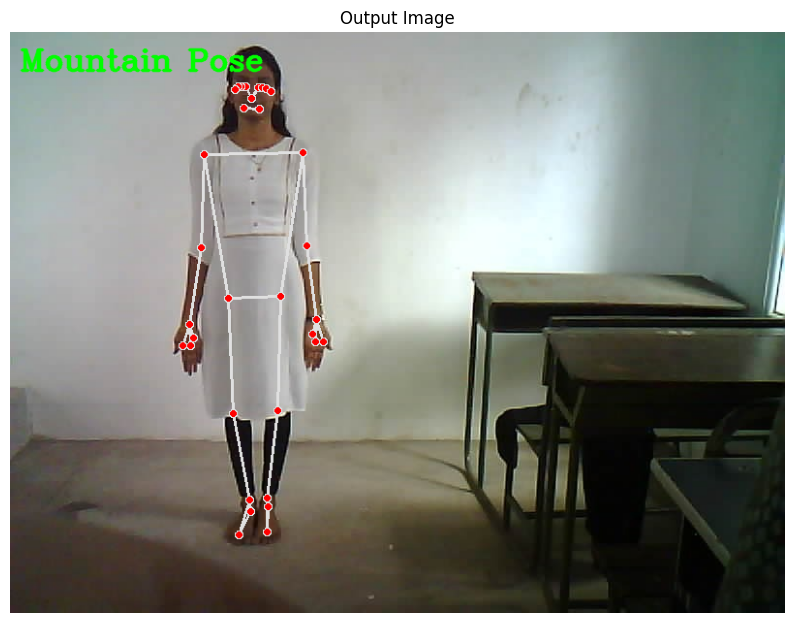

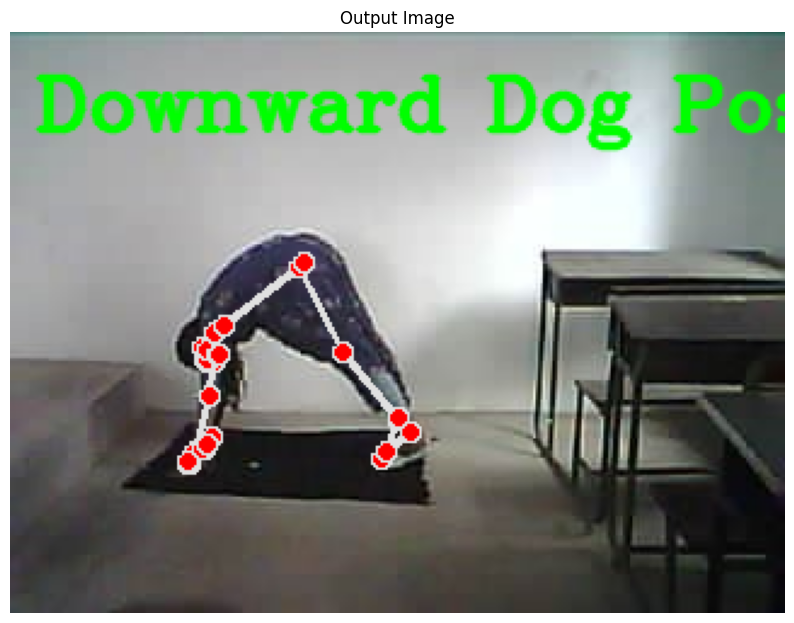

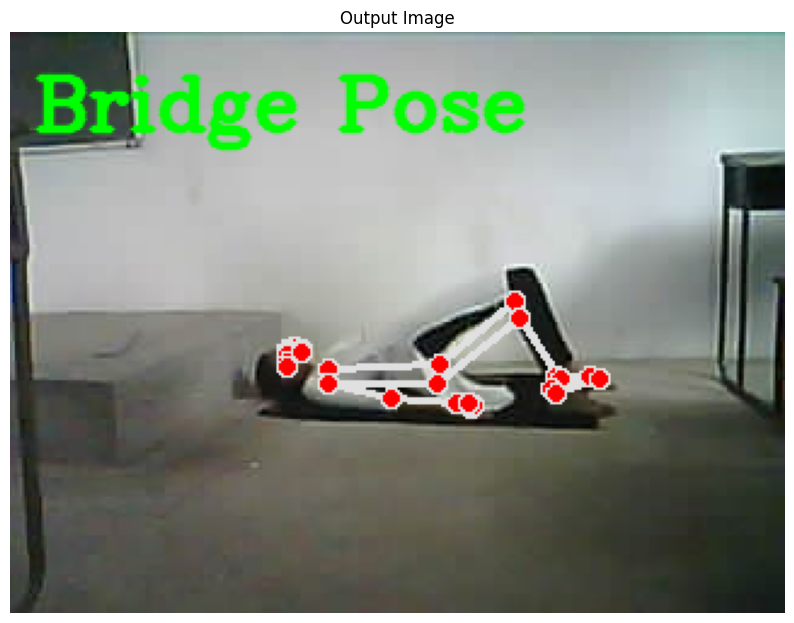

In [8]:

import os


# Initialize MediaPipe Pose
mp_pose = mp.solutions.pose

# Specify the folder containing images
folder_path = 'C:/Users/srini/OneDrive/Desktop/IMAGES'

# Loop through all files in the folder
for filename in os.listdir(folder_path):
    # Construct the full file path
    file_path = os.path.join(folder_path, filename)
    
    # Check if the file is an image
    if filename.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tiff')):
        # Read the image
        image = cv2.imread(file_path)
        
        # Process the image for pose detection
        output_image, landmarks = detectPose(image,mp_pose.Pose(static_image_mode=True, min_detection_confidence=0.5, model_complexity=0),display=False)
        
        # If landmarks are detected, classify the pose
        if landmarks:
            classifyPose(landmarks, output_image, display=True)





